In [15]:
import os, random, warnings, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

warnings.filterwarnings("ignore")
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
sns.set_theme(style="whitegrid")

print("TensorFlow", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "none (switch runtime to GPU for faster training)")

TensorFlow 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [16]:
%pip install -q kagglehub

In [17]:

try:
    import kagglehub
    path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
except Exception as e:
    print("kagglehub download failed:", e)
    print("Download the dataset zip from the Kaggle link above and upload it here (wait for 100%).")
    from google.colab import files
    up = files.upload()
    zip_name = list(up.keys())[0]
    with zipfile.ZipFile(zip_name) as z:
        z.extractall("brain_mri")
    path = "brain_mri"

def find_root(base):
    # finds the folder that contains both a Training and a Testing sub-folder
    for dp, dn, _ in os.walk(base):
        low = [d.lower() for d in dn]
        if "training" in low and "testing" in low:
            return dp
    raise FileNotFoundError("Could not find Training/Testing folders under " + base)

ROOT = find_root(path)
TRAIN_DIR = os.path.join(ROOT, next(d for d in os.listdir(ROOT) if d.lower() == "training"))
TEST_DIR  = os.path.join(ROOT, next(d for d in os.listdir(ROOT) if d.lower() == "testing"))
print("Train dir:", TRAIN_DIR)
print("Test dir :", TEST_DIR)

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Train dir: /kaggle/input/brain-tumor-mri-dataset/Training
Test dir : /kaggle/input/brain-tumor-mri-dataset/Testing


,Training,Testing
glioma,1400,400
meningioma,1400,400
notumor,1400,400
pituitary,1400,400
TOTAL,5600,1600


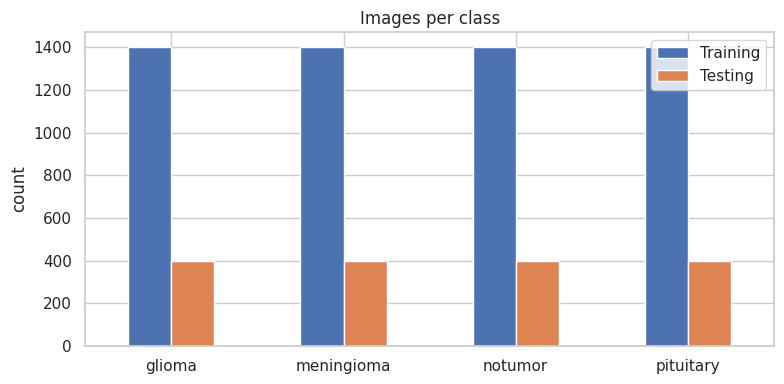

In [18]:
def count_images(folder):
    return {c: len([f for f in os.listdir(os.path.join(folder, c)) if not f.startswith(".")])
            for c in sorted(os.listdir(folder)) if os.path.isdir(os.path.join(folder, c))}

counts = pd.DataFrame({"Training": count_images(TRAIN_DIR), "Testing": count_images(TEST_DIR)})
counts.loc["TOTAL"] = counts.sum()
display(counts)

fig, ax = plt.subplots(figsize=(8, 4))
counts.drop("TOTAL").plot(kind="bar", ax=ax)
ax.set_title("Images per class"); ax.set_ylabel("count"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

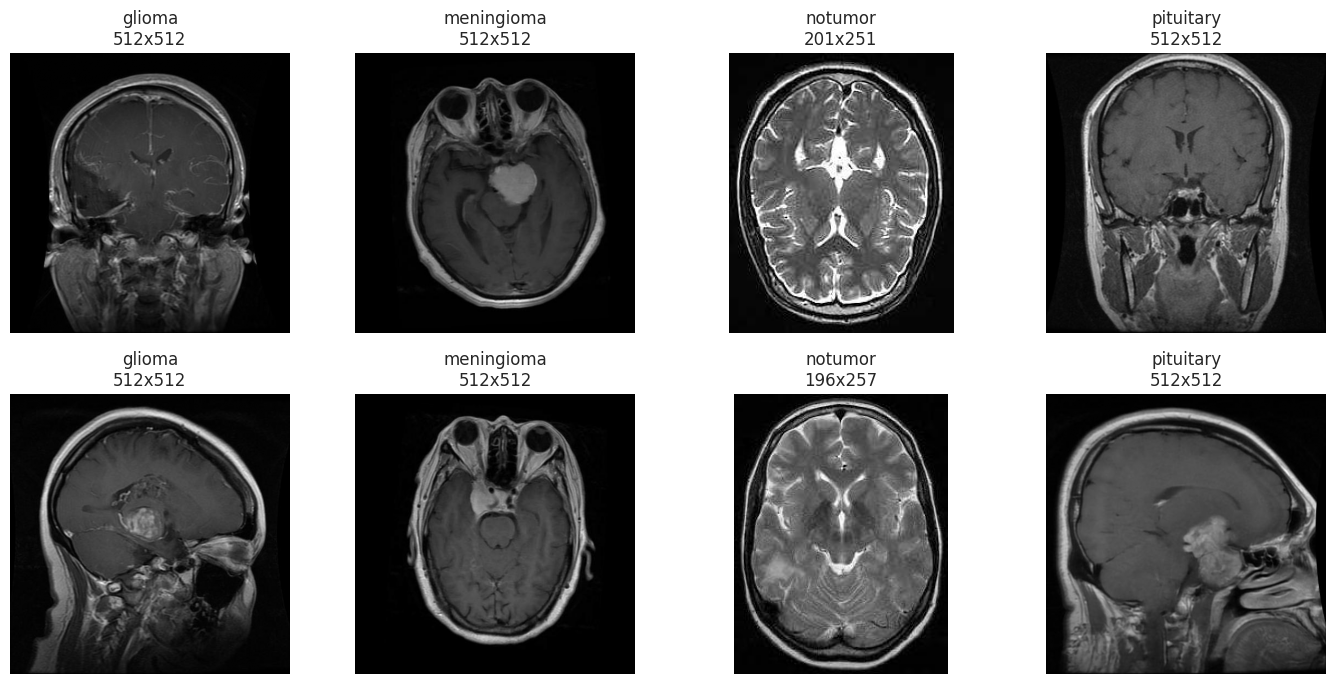

In [19]:
from PIL import Image
classes = sorted(os.listdir(TRAIN_DIR))
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for j, c in enumerate(classes):
    files_in_class = sorted(os.listdir(os.path.join(TRAIN_DIR, c)))
    for i in range(2):
        img = Image.open(os.path.join(TRAIN_DIR, c, files_in_class[i * 50]))
        axes[i, j].imshow(img, cmap="gray"); axes[i, j].axis("off")
        axes[i, j].set_title(f"{c}\n{img.size[0]}x{img.size[1]}")
plt.tight_layout(); plt.show()

In [20]:
IMG_SIZE = (128, 128)
BATCH = 32

common = dict(labels="inferred", label_mode="int", color_mode="grayscale",
              image_size=IMG_SIZE, batch_size=BATCH)

train_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.15, subset="training", seed=SEED, shuffle=True, **common)
val_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.15, subset="validation", seed=SEED, shuffle=True, **common)
test_ds = keras.utils.image_dataset_from_directory(
    TEST_DIR, shuffle=False, **common)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print("Classes:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(AUTOTUNE)
val_ds   = val_ds.cache().prefetch(AUTOTUNE)
test_ds  = test_ds.cache().prefetch(AUTOTUNE)

Found 5600 files belonging to 4 classes.
Using 4760 files for training.
Found 5600 files belonging to 4 classes.
Using 840 files for validation.
Found 1600 files belonging to 4 classes.
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [21]:
keras.backend.clear_session()
tf.random.set_seed(SEED)

def build_cnn(input_shape=(128, 128, 1), num_classes=4):
    inputs = keras.Input(shape=input_shape)
    x = layers.Rescaling(1.0 / 255)(inputs)
    # augmentation (active only during training)
    x = layers.RandomRotation(0.05)(x)
    x = layers.RandomZoom(0.1)(x)
    x = layers.RandomTranslation(0.05, 0.05)(x)
    x = layers.RandomContrast(0.1)(x)

    for filters in (32, 64, 128, 256):
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    m = keras.Model(inputs, outputs, name="brain_tumor_cnn")
    m.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
    return m

model = build_cnn(IMG_SIZE + (1,), NUM_CLASSES)
model.summary()

Model: "brain_tumor_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 1)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 128, 128, 1)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 128, 128, 1)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             

 Total params: 423,172 (1.61 MB)

 Trainable params: 422,212 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [ ]:
EPOCHS = 30
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
reduce_lr  = keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5)

history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                    callbacks=[early_stop, reduce_lr], verbose=2)

best = int(np.argmin(history.history["val_loss"]))
print(f"\nStopped after {len(history.history['loss'])} epochs | best epoch: {best + 1}")
print(f"Best val_loss: {history.history['val_loss'][best]:.4f} | val_accuracy: {history.history['val_accuracy'][best]:.4f}")

Epoch 1/30


In [ ]:
h = pd.DataFrame(history.history)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="validation")
ax[0].axvline(best, ls="--", c="gray", label="best epoch"); ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(h["accuracy"], label="train"); ax[1].plot(h["val_accuracy"], label="validation")
ax[1].axvline(best, ls="--", c="gray"); ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.4f}\n")

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_prob = model.predict(test_ds, verbose=0)
y_pred = y_prob.argmax(axis=1)

print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

In [ ]:
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0],
            xticklabels=class_names, yticklabels=class_names)
ax[0].set_title("Confusion matrix (counts)"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual")

cm_norm = cm / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", cbar=False, ax=ax[1],
            xticklabels=class_names, yticklabels=class_names)
ax[1].set_title("Confusion matrix (row-normalised = per-class recall)"); ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("Actual")
plt.tight_layout(); plt.show()

In [ ]:
x_test = np.concatenate([x.numpy() for x, _ in test_ds]).astype("uint8")
wrong = np.where(y_pred != y_true)[0]
right = np.where(y_pred == y_true)[0]
print(f"Misclassified: {len(wrong)} of {len(y_true)}")

def show(idx, title, n=8):
    idx = idx[:n]
    if len(idx) == 0:
        return
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for a in axes.ravel():
        a.axis("off")
    for a, i in zip(axes.ravel(), idx):
        a.imshow(x_test[i].squeeze(), cmap="gray")
        a.set_title(f"true: {class_names[y_true[i]]}\npred: {class_names[y_pred[i]]} ({y_prob[i].max():.2f})", fontsize=10)
    fig.suptitle(title); plt.tight_layout(); plt.show()

rng = np.random.default_rng(SEED)
show(rng.permutation(right), "Correct predictions (random sample)")
show(rng.permutation(wrong), "Misclassified images (random sample)")

In [ ]:
model.save("brain_tumor_cnn.keras")
print("Saved brain_tumor_cnn.keras")

In [ ]:
import joblib

# Trained (compiled) CNN -> .joblib  (also saved in Keras's own .keras format)
try:
    joblib.dump(model, "brain_tumor_cnn.joblib")
    print("Saved brain_tumor_cnn.joblib (full Keras model)")
except Exception as e:
    # fallback for older Keras versions: save architecture + weights instead
    joblib.dump({"architecture": model.to_json(), "weights": model.get_weights()}, "brain_tumor_cnn.joblib")
    print("Saved architecture + weights bundle (fallback):", e)
joblib.dump(class_names, "brain_tumor_class_names.joblib")
model.save("brain_tumor_cnn.keras")

# Reload and check that it reproduces the test predictions
loaded = joblib.load("brain_tumor_cnn.joblib")
if isinstance(loaded, dict):
    loaded_model = keras.models.model_from_json(loaded["architecture"])
    loaded_model.set_weights(loaded["weights"])
else:
    loaded_model = loaded
p_reload = loaded_model.predict(test_ds, verbose=0)
print("Reloaded model matches original predictions:", np.allclose(p_reload, y_prob, atol=1e-3))